# Imports

In [1]:
%load_ext autoreload
%autoreload 2

# System libraries.
import logging

# Third-party libraries.
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
# Use this for most notebooks.
import helpers.hdbg as hdbg
import helpers.hnotebook as hnotebook

_LOG = logging.getLogger(__name__)

# Initialize notebook configuration and logging.
hdbg.init_logger(verbosity=logging.INFO)
hnotebook.config_notebook()

# Convert `display` into `print()`.
try:
    from IPython.display import display
except ImportError:
    display = print  # type: ignore

INFO  > /usr/local/lib/python3.12/site-packages/ipykernel_launcher.py -f /root/.local/share/jupyter/runtime/kernel-c659c02c-ad34-42da-b91e-e02f6ddf9554.json


# Load Data

Heart disease dataset for binary classification. The Cleveland dataset has very few missing values and the combined dataset has many missing values in certain columns. The combined dataset also has one additional column for which institute the record came from.

In [3]:
heart_disease_cleveland = pd.read_csv('./datasets/heart_disease_cleveland.csv')
heart_disease_combined = pd.read_csv('./datasets/heart_disease_combined.csv')

In [4]:
heart_disease_cleveland.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [5]:
heart_disease_combined = heart_disease_combined.drop(columns=['source'])
heart_disease_combined.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


NYC Yellow Taxi dataset for regression

In [15]:
yellow_taxi = pd.read_parquet('./datasets/yellow_tripdata_2026-09.parquet')

In [16]:
yellow_taxi = yellow_taxi.drop(columns=['store_and_fwd_flag','request_source']).sample(n=1000,random_state=42)
yellow_taxi.head()

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee
2494061,1,2026-09-29 02:16:28,2026-09-29 02:25:39,1.0,2.30,1.0,249,48,1,11.40,4.25,0.5,3.45,0.00,1.0,20.60,2.5,0.0,0.75
723703,2,2026-09-10 01:56:18,2026-09-10 02:01:03,1.0,1.09,1.0,114,125,1,7.90,1.00,0.5,2.73,0.00,1.0,16.38,2.5,0.0,0.75
241958,2,2026-09-03 21:33:38,2026-09-03 21:56:00,1.0,3.33,1.0,79,48,2,21.20,1.00,0.5,0.00,0.00,1.0,26.95,2.5,0.0,0.75
2939295,2,2026-09-08 20:06:27,2026-09-08 20:23:27,NaN,3.23,NaN,162,107,0,24.78,0.00,0.5,0.00,0.00,1.0,32.48,NaN,NaN,0.75
1065973,2,2026-09-13 15:48:17,2026-09-13 16:15:40,2.0,9.04,1.0,138,238,1,38.70,5.00,0.5,11.03,7.46,1.0,68.19,2.5,2.0,0.00


# EDA

## Heart Disease Cleveland

### Manual

number of rows: 303
number of missing values:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64
mean values:
age          54.438944
sex           0.679868
cp            3.158416
trestbps    131.689769
chol        246.693069
fbs           0.148515
restecg       0.990099
thalach     149.607261
exang         0.326733
oldpeak       1.039604
slope         1.600660
ca            0.672241
thal          4.734219
target        0.458746
dtype: float64


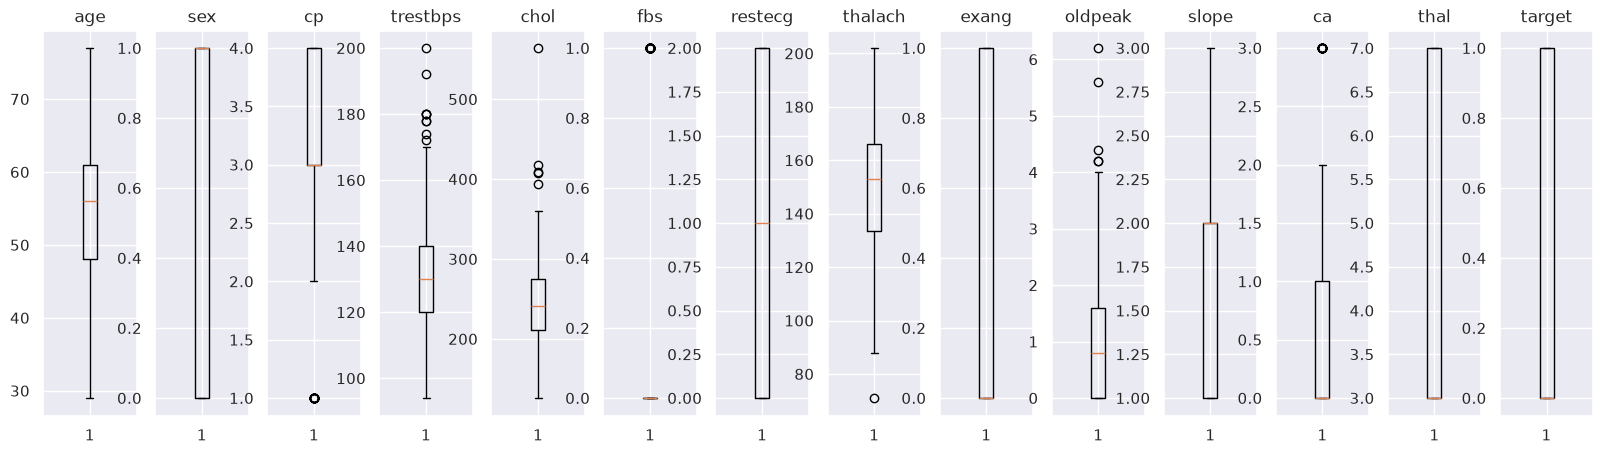

In [27]:
num_rows = len(heart_disease_cleveland)
print('number of rows:',num_rows)
print('number of missing values:')
print(heart_disease_cleveland.isna().sum())
print('mean values:')
print(heart_disease_cleveland.mean())

columns = heart_disease_cleveland.columns
fig, (axs) = plt.subplots(1, 14)

for i in range(len(axs)):
    axs[i].boxplot(heart_disease_cleveland[columns[i]].dropna())
    axs[i].set_title(columns[i])
plt.show()

## Heart Disease Combined

### Manual

number of rows: 920
number of missing values:
age           0
sex           0
cp            0
trestbps     59
chol         30
fbs          90
restecg       2
thalach      55
exang        55
oldpeak      62
slope       309
ca          611
thal        486
target        0
dtype: int64
mean values:
age          53.510870
sex           0.789130
cp            3.250000
trestbps    132.132404
chol        199.130337
fbs           0.166265
restecg       0.604575
thalach     137.545665
exang         0.389595
oldpeak       0.878788
slope         1.770867
ca            0.676375
thal          5.087558
target        0.553261
dtype: float64


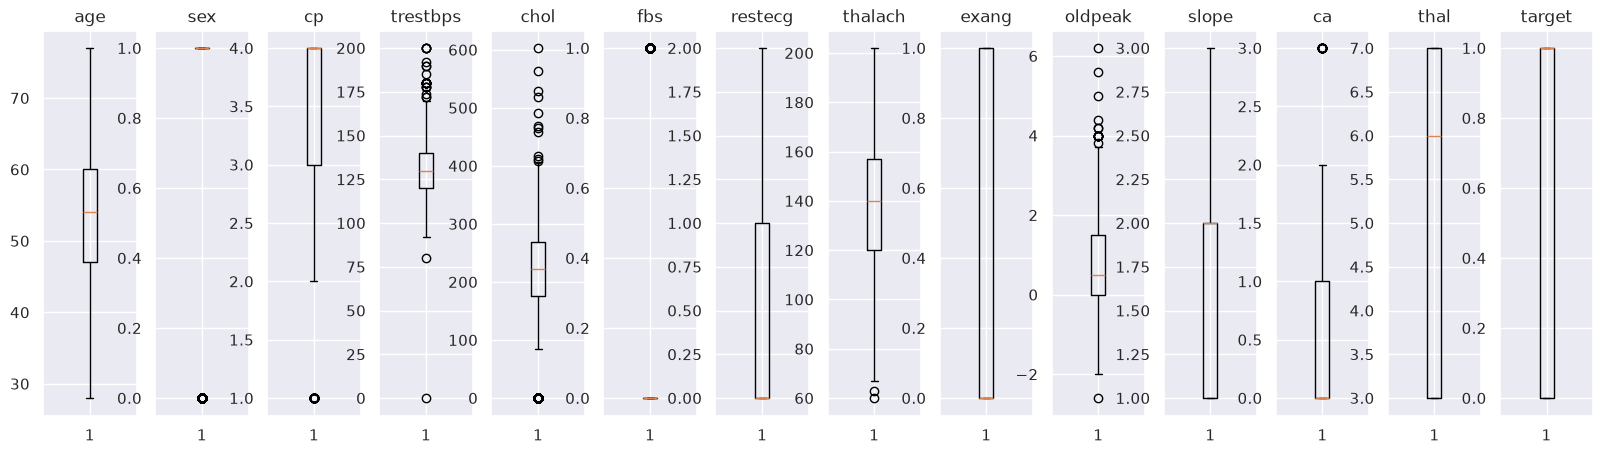

In [34]:
num_rows = len(heart_disease_combined)
print('number of rows:',num_rows)
print('number of missing values:')
print(heart_disease_combined.isna().sum())
print('mean values:')
print(heart_disease_combined.mean())

columns = heart_disease_combined.columns
fig, (axs) = plt.subplots(1, 14)

for i in range(len(axs)):
    axs[i].boxplot(heart_disease_combined[columns[i]].dropna())
    axs[i].set_title(columns[i])
plt.show()

## Yellow Taxi

### Manual

number of rows: 1000
number of missing values:
VendorID                   0
tpep_pickup_datetime       0
tpep_dropoff_datetime      0
passenger_count          289
trip_distance              0
RatecodeID               289
PULocationID               0
DOLocationID               0
payment_type               0
fare_amount                0
extra                      0
mta_tax                    0
tip_amount                 0
tolls_amount               0
improvement_surcharge      0
total_amount               0
congestion_surcharge     289
Airport_fee              289
cbd_congestion_fee         0
dtype: int64
mean values:
VendorID                                      1.932
tpep_pickup_datetime     2026-09-16 03:19:05.192000
tpep_dropoff_datetime    2026-09-16 03:37:15.301999
passenger_count                            1.232068
trip_distance                               3.47289
RatecodeID                                  6.16315
PULocationID                                161.442
DOLocationID

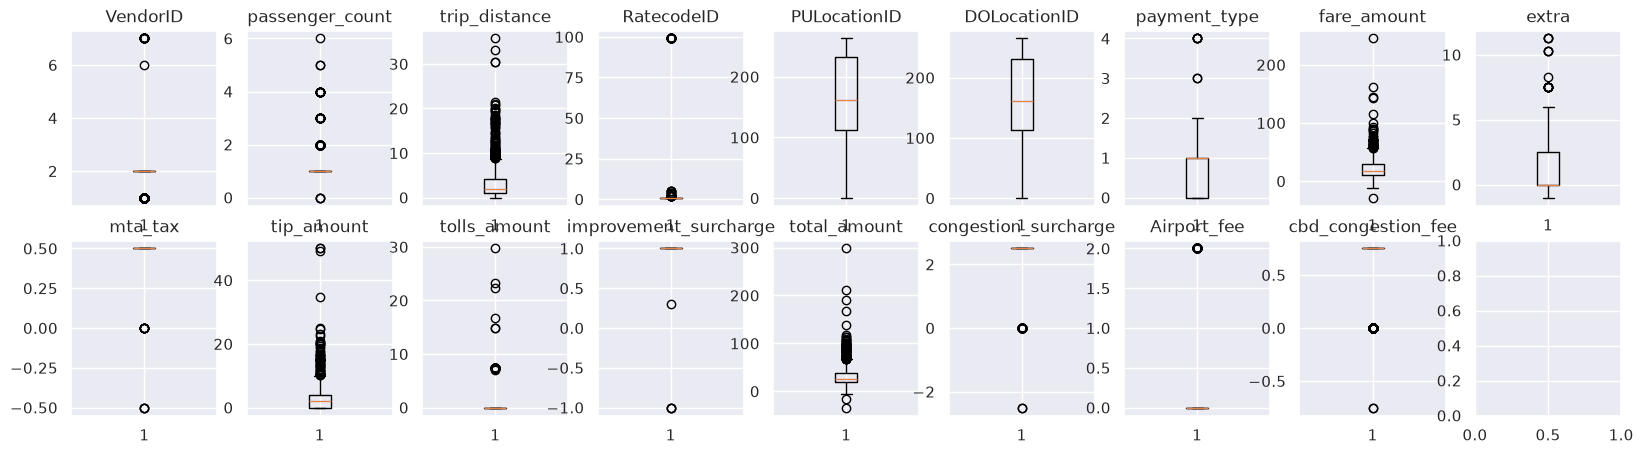

In [19]:
num_rows = len(yellow_taxi)
print('number of rows:',num_rows)
print('number of missing values:')
print(yellow_taxi.isna().sum())
print('mean values:')
print(yellow_taxi.mean())

columns = yellow_taxi.drop(columns=['tpep_pickup_datetime','tpep_dropoff_datetime']).columns
fig, (axs) = plt.subplots(2, 9)

for i in range(len(columns)):
    axs[i//9][i%9].boxplot(yellow_taxi[columns[i]].dropna())
    axs[i//9][i%9].set_title(columns[i])
plt.show()